# Suggest a ligand-pair batch: repository method + MaxMin or Sobol

**Start here:** launch Jupyter inside a GPU allocation using [README.md](README.md), then choose **Kernel → Restart Kernel and Run All Cells** (or select each cell and press **Shift+Enter**). Change only the settings and prompt cells when you want a different proposal.

This notebook first runs the repository's existing **Claude-rank + embedding-diversity consensus**. It chooses a diverse subset of those suggestions in scaled PCA space, then fills the remaining slots with **MaxMin** or **Sobol** points in a PCA representation of T5-base prompt embeddings.

- Defaults: **48 pairs = 24 repository suggestions + 24 Sobol selections**. Section 8 checks whether all 30 active ligands are covered.
- T5-base embeds the current prompts directly in this GPU-backed notebook kernel during each run. The saved Claude ranking needs **no Claude API calls or API key**.
- The first run downloads T5-base weights from Hugging Face, unless you supply a local model folder. Later runs reuse the model weights and recompute the pair embeddings.
- These are reviewable proposals. The notebook does not start equipment or change the archived campaign.

Everything runs in ordinary Python cells. Results stay in memory unless you enable `SAVE_RESULTS`.


## 1. Imports and GPU check

Run this notebook in a **GPU-backed Jupyter server**, using the `dual-ligand-notebook` environment. The cluster launch command is in [README.md](README.md). Choosing the Conda environment on a login node does not allocate a GPU.

All added code runs directly in the notebook. The repository imports below use its existing inventory, I/O and selection functions.


In [41]:
from pathlib import Path
from datetime import datetime, timezone
import sys
import importlib.metadata
import hashlib
import string
import hte

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, T5EncoderModel
from IPython.display import display

from hte.io import read_json, read_csv, digest, object_digest, write_csv, write_json, new_output
from hte.inventory import campaign_inventory, candidates
from hte.design import consensus_select, ranked_ids


In [42]:
device = torch.device("cuda")
torch.set_num_threads(2)
print(f"GPU: {torch.cuda.get_device_name(0)}")

GPU: NVIDIA H100 MIG 2g.24gb


## 2. Choose your batch settings

Change the values below, then run all cells underneath.

| Setting | Meaning |
|---|---|
| `BATCH_SIZE` | Total number of different pairs to suggest. |
| `KEEP_FROM_REPO` | How many repository suggestions to retain, chosen by diversity in scaled PCA space. When requested and enough subset slots are available, ligand coverage takes priority over distance. The rest come from sampling. Set it to `BATCH_SIZE` to retain all repository suggestions, or `0` for sampling alone. |
| `SAMPLER` | `"sobol"` or `"maxmin"`. MaxMin picks pairs far from those already selected; Sobol matches space-filling targets to real pairs. |
| `PCA_DIMENSIONS` | Number of PCA coordinates; 16 follows the ALICE example. |
| `SEED` | Repeatable sampling: unchanged settings, data and software produce the same proposal. |
| `PREVIOUS_EXPERIMENTS_CSV` | Optional earlier design/results CSV with a `pair_id` column. Those pairs are excluded. `None` starts a fresh batch. This excludes experiments; it does not retrain Claude. |
| `REQUIRE_ALL_LIGANDS` | Require ligand coverage in the repository baseline, then check coverage of the mixed batch in section 8. Sampling does not force coverage; the check raises an error if any ligand is missing. |

MaxMin is sometimes informally called “minmax”; the code uses `"maxmin"`.

`SAVE_RESULTS = False` keeps the proposal in memory. Set it to `True` only when you want to export CSVs and settings.


In [43]:
REPO_ROOT = Path(hte.__file__).resolve().parent.parent

BATCH_SIZE = 48
KEEP_FROM_REPO = 24
SAMPLER = "sobol"  # Choose "sobol" or "maxmin".
PCA_DIMENSIONS = 16 # keep that as it is 
SEED = 1 # keep that as it is
REQUIRE_ALL_LIGANDS = True
SAVE_RESULTS = False  # Set True only when you want CSV export.

RANKING_CSV = REPO_ROOT / "campaigns/hackathon2026/scoring/ranking.csv"
PREVIOUS_EXPERIMENTS_CSV = None  # Example: REPO_ROOT / "output/earlier_run/suggested_batch.csv"
MODEL_PATH = "google-t5/t5-base"  # Or the path to a local T5-base model directory.


## 3. Review or edit the reaction prompt

There is **one prompt per candidate pair**, with the two ligand structures substituted below. Tokens are encoded with **T5-base**, pooled using the attention mask, and averaged over both ligand orders so A+B and B+A represent the same pair.

Keep `{ligand_a_smiles}` and `{ligand_b_smiles}` in your text. Ligand names are optional. Every run embeds this text after substituting the ligand names and structures, including when the default text is unchanged.

**The saved Claude scores describe the original campaign conditions.** If you change the chemistry (temperature, solvent, substrate, loadings, etc.), obtain a matching ranking using the repository scoring workflow and update `RANKING_CSV`. Changing this embedding prompt alone does not update Claude's scores. For a wording change, the existing ranking can still be compared.


In [44]:
PROMPT_TEMPLATE = (
    "Pd desulfonylative fluorination in toluene at 95 C. "
    "Ligand 1 {ligand_a_name} {ligand_a_smiles} 6 mol%. "
    "Ligand 2 {ligand_b_name} {ligand_b_smiles} 6 mol%. "
    "Pd 12 mol%. Substrate pyridine-2-sulfonyl fluoride 0.1 M."
)
print(PROMPT_TEMPLATE)


Pd desulfonylative fluorination in toluene at 95 C. Ligand 1 {ligand_a_name} {ligand_a_smiles} 6 mol%. Ligand 2 {ligand_b_name} {ligand_b_smiles} 6 mol%. Pd 12 mol%. Substrate pyridine-2-sulfonyl fluoride 0.1 M.


## 4. Load the campaign, candidate pairs and Claude scores

- The notebook uses the repository's inventory checks and pair IDs. 

- The unavailable L07 stays excluded. 

- Scores must cover every candidate exactly once, or exactly the untested pairs when an exclusion CSV is supplied. A score is a ranking value, **not predicted percentage yield**.


In [45]:
# We use t5-base as per ALICE 
MODEL = "google-t5/t5-base"
MODEL_REVISION = "a9723ea7f1b39c1eae772870f3b547bf6ef7e6c1"
DEFAULT_PROMPT = PROMPT_TEMPLATE

In [70]:
# This function will simply wrap the prompt template to generate both ligand orders for each candidate pair.
# Then we can take the average of the embeddings
def pair_prompts(inventory, candidates, template=DEFAULT_PROMPT):
    """Return both ligand orders; reject templates that omit either structure."""

    fields = {field for _, field, _, _ in string.Formatter().parse(template) if field}
    required = {"ligand_a_smiles", "ligand_b_smiles"}
    allowed = required | {"ligand_a_name", "ligand_b_name"}

    if not required <= fields or fields - allowed:
        raise ValueError("Prompt needs {ligand_a_smiles} and {ligand_b_smiles}; "
                         "optional fields are {ligand_a_name} and {ligand_b_name}.")
    
    prompts = []
    for pair in candidates:
        a, b = inventory[pair["ligand_a"]], inventory[pair["ligand_b"]]
        for first, second in ((a, b), (b, a)):
            prompts.append(template.format(ligand_a_name=first["name"], ligand_a_smiles=first["smiles"], ligand_b_name=second["name"], ligand_b_smiles=second["smiles"]))
    return prompts

In [71]:
# This function will load previously excluded pairs from a CSV file.
def load_excluded_pairs(path, candidates):
    """Accept an earlier design/results CSV; only nonempty pair IDs are excluded."""

    if path is None:
        return set()
    
    rows = read_csv(path)
    if not rows or "pair_id" not in rows[0]:
        raise ValueError("Previous-experiments CSV must contain a pair_id column")
    excluded = {r["pair_id"] for r in rows if r["pair_id"] and r.get("kind", "pair") == "pair"}
    unknown = excluded - {c["pair_id"] for c in candidates}
    
    if unknown:
        raise ValueError("Previous-experiments CSV contains unknown pairs: " + ", ".join(sorted(unknown)))
    return excluded


In [73]:
CONFIG_PATH = REPO_ROOT / "hte_inputs/campaign.json"
LIGAND_COLLECTION_PATH = REPO_ROOT / "hte_inputs/ligands.csv"

In [74]:
config = read_json(CONFIG_PATH)
inventory = campaign_inventory(LIGAND_COLLECTION_PATH, config)
all_candidates = candidates(inventory)
ranking = read_csv(RANKING_CSV)
excluded = load_excluded_pairs(PREVIOUS_EXPERIMENTS_CSV, all_candidates)

ranked_ids(ranking, all_candidates if {r["pair_id"] for r in ranking} == {c["pair_id"] for c in all_candidates}
           else [c for c in all_candidates if c["pair_id"] not in excluded])

required_ligands = set(inventory) if REQUIRE_ALL_LIGANDS else set()

candidate_table = pd.DataFrame(all_candidates)
score_table = pd.DataFrame(ranking)

for column in ("mean_score", "score_sd"):
    score_table[column] = pd.to_numeric(score_table[column])

print(f"{len(inventory)} active ligands: {len(all_candidates)} possible pairs")
print(f"{len(excluded)} previously tested pairs excluded")
# this will be our goal
print(f"This proposal: {KEEP_FROM_REPO} repository + {BATCH_SIZE - KEEP_FROM_REPO} {SAMPLER}")
display(score_table.head(10))


30 active ligands: 435 possible pairs
0 previously tested pairs excluded
This proposal: 24 repository + 24 sobol


,pair_id,mean_score,score_sd,scoring_calls
0,L05__L06,70.0,2.828427,5
1,L01__L17,68.8,1.788854,5
2,L03__L06,67.6,0.894427,5
3,L05__L11,65.6,3.577709,5
4,L15__L18,65.2,1.095445,5
5,L16__L18,65.2,6.418723,5
6,L03__L11,64.8,1.303840,5
7,L04__L17,64.8,4.604346,5
8,L10__L17,64.8,1.095445,5
9,L16__L17,64.8,4.604346,5


## 5. Generate fresh T5-base embeddings directly on the GPU

The next cell loads T5-base onto this notebook kernel's GPU. The following cell tokenizes and embeds all 435 pairs in both ligand orders, pools using the attention mask and returns one 768-dimensional vector per pair.

All tensors and embeddings stay in memory. There is no separate worker, Slurm submission from a cell, request file or intermediate embedding file. Each execution recomputes the embeddings. Model weights use Hugging Face's normal download cache.


In [75]:
# Load T5-base directly in this GPU-backed notebook kernel.
model_info = {"model": MODEL_PATH, "revision": MODEL_REVISION}
if MODEL_PATH != MODEL:
    model_dir = Path(MODEL_PATH).expanduser().resolve()
    if not (model_dir / "config.json").is_file():
        raise ValueError("MODEL_PATH must be google-t5/t5-base or a local T5-base folder")
    model_info = {"model": str(model_dir), "revision": None}

model_options = {"revision": model_info["revision"]} if model_info["revision"] else {"local_files_only": True}
tokenizer = AutoTokenizer.from_pretrained(model_info["model"], **model_options)
encoder = T5EncoderModel.from_pretrained(model_info["model"], **model_options)
encoder = encoder.eval().requires_grad_(False).to(device)
print(f"T5-base loaded on {torch.cuda.get_device_name(0)}")


T5-base loaded on NVIDIA H100 MIG 2g.24gb


In [76]:
# Compute fresh embeddings in memory; no embedding files are read or written.
ordered_prompts = pair_prompts(inventory, all_candidates, PROMPT_TEMPLATE)
print("Example candidate prompt:")
print(ordered_prompts[0])

vectors = []

with torch.inference_mode():
    for start in range(0, len(ordered_prompts), 8):
        batch = ordered_prompts[start:start+8]
        tokens = tokenizer(batch, return_tensors="pt", padding=True, truncation=False)

        if tokens.input_ids.shape[1] > 512: # Limit at 512 tokens
            raise ValueError("Prompt exceeds 512 tokens. Shorten it while keeping both ligand structures.")

        tokens = tokens.to(device) 
        hidden = encoder(**tokens).last_hidden_state
        mask = tokens.attention_mask.unsqueeze(-1)
        pooled = (hidden * mask).sum(1) / mask.sum(1)

        # Print intermediate dimensions for the first batch only.
        if start == 0:
            print("First batch dimensions:")
            print(f"Input IDs: {tuple(tokens.input_ids.shape)}")
            print(f"Attention mask: {tuple(tokens.attention_mask.shape)}")
            print(f"Hidden states: {tuple(hidden.shape)}")
            print(f"Expanded mask: {tuple(mask.shape)}")
            print(f"Pooled vectors: {tuple(pooled.shape)}")

        vectors.extend(pooled.cpu().numpy())

        if start % 80 == 0 or start+8 >= len(ordered_prompts): 
            print(f"Embedded {min(start+8, len(ordered_prompts))}/{len(ordered_prompts)} ordered prompts")

# Transform the list of vectors into a numpy array 
ordered_vectors = np.asarray(vectors)
print(f"\nAll ordered embeddings: {ordered_vectors.shape}")

paired_vectors = ordered_vectors.reshape(len(all_candidates), 2, -1)
print(f"Grouped by ligand pair: {paired_vectors.shape}")

features = paired_vectors.mean(axis=1)
print(f"After averaging orders: {features.shape}")

if features.shape != (len(all_candidates), 768) or not np.isfinite(features).all():
    raise ValueError("Expected one finite 768-dimensional T5-base vector per pair")

embedding_info = {
    "source": "generated", "device": "cuda", "gpu_name": torch.cuda.get_device_name(0),
    "python_executable": sys.executable, "torch_version": torch.__version__,
    "prompts_sha256": object_digest(ordered_prompts),
    "features_sha256": hashlib.sha256(features.tobytes()).hexdigest(),
    "pooling": "masked_mean_then_mean_of_both_ligand_orders", **model_info,
}
print(f"Embedding matrix: {features.shape}") #  features stores all the embeddings

Example candidate prompt:
Pd desulfonylative fluorination in toluene at 95 C. Ligand 1 MorDal Phos C1CN(CCO1)c2ccccc2P([C@@]34C[C@@H]5C[C@@H](C[C@@H](C5)C3)C4)[C@@]67C[C@@H]8C[C@@H](C[C@@H](C8)C6)C7 6 mol%. Ligand 2 racBINAP P(c8ccccc8)(c7ccccc7)c1c(c6c(cc1)cccc6)c2c3c(ccc2P(c5ccccc5)c4ccccc4)cccc3 6 mol%. Pd 12 mol%. Substrate pyridine-2-sulfonyl fluoride 0.1 M.
First batch dimensions:
Input IDs: (8, 266)
Attention mask: (8, 266)
Hidden states: (8, 266, 768)
Expanded mask: (8, 266, 1)
Pooled vectors: (8, 768)
Embedded 8/870 ordered prompts
Embedded 88/870 ordered prompts
Embedded 168/870 ordered prompts
Embedded 248/870 ordered prompts
Embedded 328/870 ordered prompts
Embedded 408/870 ordered prompts
Embedded 488/870 ordered prompts
Embedded 568/870 ordered prompts
Embedded 648/870 ordered prompts
Embedded 728/870 ordered prompts
Embedded 808/870 ordered prompts
Embedded 870/870 ordered prompts

All ordered embeddings: (870, 768)
Grouped by ligand pair: (435, 2, 768)
After averaging o

In [77]:
print("\nText encoded by T5:")
print(batch[0])

print("\nToken embeddings shape:")
print(tuple(hidden[0].shape))  # (number of tokens, 768)

print("\nPooled prompt embedding shape:")
print(tuple(pooled[0].shape))  # (768,)

print("\nFirst 10 embedding values:")
print(pooled[0, :10].cpu().numpy())


Text encoded by T5:
Pd desulfonylative fluorination in toluene at 95 C. Ligand 1 meCgPPh C12(C)CC3(C)OC(C)(CC(C)(O3)O1)P2C1=CC=CC=C1 6 mol%. Ligand 2 N-XantPhos N1c2cccc(P(c3ccccc3)c4ccccc4)c2Oc5c1cccc5P(c6ccccc6)c7ccccc7 6 mol%. Pd 12 mol%. Substrate pyridine-2-sulfonyl fluoride 0.1 M.

Token embeddings shape:
(183, 768)

Pooled prompt embedding shape:
(768,)

First 10 embedding values:
[-0.17983168  0.06790811 -0.17776446  0.12273412  0.12563843  0.01028271
  0.12210444 -0.02698069 -0.2577633  -0.13555603]


In [78]:
total = len(features)
unique = len(np.unique(features, axis=0))
duplicates = total - unique

print(f"Total embeddings: {total}")
print(f"Unique embeddings: {unique}")
print(f"Duplicate embeddings: {duplicates}")

Total embeddings: 435
Unique embeddings: 435
Duplicate embeddings: 0


## 6. Reduce embeddings with PCA

Following ALICE: **standardize the embedding dimensions → PCA → scale each retained component to [0, 1]**. Sampling uses all retained components, while plots show just the first two. The retained variance tells you how much embedding variation remains.


In [79]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [80]:
def pca_coordinates(features, dimensions=16, seed=42):
    """ALICE-style StandardScaler -> PCA -> MinMaxScaler."""

    x = np.asarray(features, dtype=float)
    if x.ndim != 2 or not np.isfinite(x).all() or len(x) < 2:
        raise ValueError("PCA requires at least two finite embedding rows")
    if type(dimensions) is not int or not 1 <= dimensions <= min(x.shape[0]-1, x.shape[1]):
        raise ValueError(f"PCA dimensions must be an integer from 1 to {min(x.shape[0]-1, x.shape[1])}")
    if not np.any(np.ptp(x, axis=0)):
        raise ValueError("All embeddings are identical; PCA cannot describe diversity")
    standardized = StandardScaler().fit_transform(x)
    pca = PCA(n_components=dimensions, svd_solver="full", random_state=seed)
    components = pca.fit_transform(standardized)
    coordinates = MinMaxScaler().fit_transform(components)
    return coordinates, components, pca.explained_variance_ratio_


PCA coordinates: (435, 16)
Variance retained: 89.4%


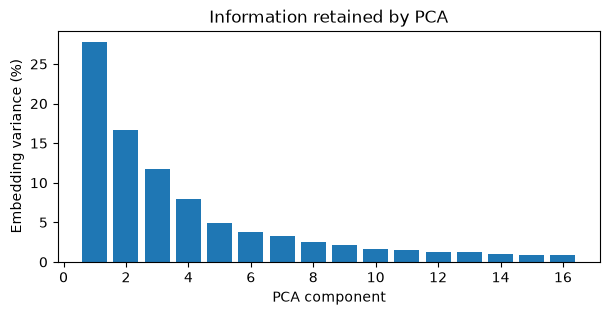

In [81]:
coordinates, pca_components, explained_variance = pca_coordinates(features, dimensions=PCA_DIMENSIONS, seed=SEED,)   
print(f"PCA coordinates: {coordinates.shape}")
print(f"Variance retained: {explained_variance.sum():.1%}")
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(np.arange(1, len(explained_variance)+1), explained_variance * 100)
ax.set(xlabel="PCA component", ylabel="Embedding variance (%)", title="Information retained by PCA")
plt.show()


In [82]:
coordinates, pca_components, explained_variance = pca_coordinates(
    features,
    dimensions=PCA_DIMENSIONS,
    seed=SEED,
)

print(f"Original embeddings: {features.shape}")
print(f"After PCA: {pca_components.shape}")
print(f"Scaled coordinates: {coordinates.shape}")
print(f"Dimensions reduced: {features.shape[1]} to {coordinates.shape[1]}")

Original embeddings: (435, 768)
After PCA: (435, 16)
Scaled coordinates: (435, 16)
Dimensions reduced: 768 to 16


## 7. Suggest the mixed batch

**Repository branch:** the existing `consensus_select()` combines Claude percentile and embedding-diversity percentile with the campaign's configured weights and score cutoff, using the fresh T5-base embeddings from section 5. We select `KEEP_FROM_REPO` pairs from its full suggested batch using the existing selector with diversity weight 100%, in scaled PCA space. The first distance is measured from the subset centroid; subsequent distances are to the nearest already retained pair. If ligand coverage is requested and the subset has at least one slot per two required ligands, covering missing ligands takes priority. Claude scores only break diversity-rank ties. This is a greedy selection, not a globally optimal subset.

**Sampling branch:** fills the other slots with unselected, untested pairs:

- **MaxMin:** repeatedly selects the point farthest from its nearest selected point in the scaled PCA space. Retained repository points are initial anchors. With no anchors, the first point is chosen using the seed.
- **Sobol:** generates scrambled Sobol targets in the PCA unit box, then greedily matches the closest unused target–candidate pair, removing both. This follows ALICE's matching idea. SciPy generates the Sobol sequence here, rather than ALICE's PyTorch engine; identical seeds need not produce identical points across implementations.

The next cell computes the full repository baseline and chooses the diverse subset using the existing diversity selector. The following cells fill the remaining batch slots and label the selected pairs for the tables and plots. The sampling branch explores **all remaining pairs**, including those below the baseline Claude cutoff. This is a count-based mixture, separate from the baseline's internal 50/50 rank weighting.

The full baseline enforces ligand coverage when requested. The retained repository subset also enforces coverage when it has enough slots; otherwise coverage relies on the sampled additions. The mixed batch is checked in section 8; the filling sampler does not adjust selections to force coverage.

A non-power-of-two Sobol target count (24 by default) and finite-candidate matching do **not** retain the exact balance guarantees of a power-of-two continuous Sobol design.


In [83]:
import numpy as np
from scipy.stats import qmc
from scipy.spatial.distance import cdist


def suggest_mixed_batch(
    candidates, 
    baseline, 
    coordinates,
    count=48, 
    keep=24, 
    sampler="sobol", 
    seed=42, 
    excluded=(),
):
    if sampler not in ("sobol", "maxmin") or not 0 <= keep <= count:
        raise ValueError("Check sampler and batch sizes.")

    # Convert coordinates to a NumPy array and extract candidate IDs
    coordinates = np.asarray(coordinates)
    ids = [c["pair_id"] for c in candidates]
    excluded = set(excluded)

    # Keep unique, untested repository suggestions.
    kept_ids = list(dict.fromkeys(
        pair_id for pair_id in baseline if pair_id not in excluded
    ))[:keep]

    # Determine the indices of the kept suggestions in the candidate list
    chosen = [ids.index(pair_id) for pair_id in kept_ids]
    available = [
        i for i, pair_id in enumerate(ids)
        if pair_id not in excluded and i not in chosen
    ]

    # Ensure there are enough available suggestions to fill the remaining batch
    if len(chosen) != keep or count - keep > len(available):
        raise ValueError("Not enough eligible suggestions.")

    remaining = count - keep
    rng = np.random.default_rng(seed)

    # Initialize the Sobol sequence engine from qmc.Sobol
    if sampler == "sobol" and remaining:
        engine = qmc.Sobol(d=coordinates.shape[1], scramble=True, seed=seed)
        targets = engine.random_base2(
            (remaining - 1).bit_length()
        )[:remaining]

    for _ in range(remaining):
        if sampler == "sobol":
            distances = cdist(targets, coordinates[available])
            row, column = np.unravel_index(
                distances.argmin(), distances.shape
            )
            targets = np.delete(targets, row, axis=0)

        elif chosen:
            distances = cdist(
                coordinates[available], coordinates[chosen]
            )
            column = distances.min(axis=1).argmax()

        else:
            column = rng.integers(len(available))

        chosen.append(available.pop(int(column)))

    return [ids[i] for i in chosen]

In [84]:
# Compute the repository baseline using only untested pairs.
available = [
    i for i, candidate in enumerate(all_candidates)
    if candidate["pair_id"] not in excluded
]
pool = [all_candidates[i] for i in available]
pool_ids = {candidate["pair_id"] for candidate in pool}

baseline_ids, baseline_trace = consensus_select(
    pool,
    [row for row in ranking if row["pair_id"] in pool_ids],
    np.asarray(features)[available],
    count=BATCH_SIZE,
    weight=config["design"]["consensus_weight_llm"],
    minimum_percentile=config["design"]["minimum_llm_percentile"],
    required_ligands=required_ligands,
)

# Spread the repository LLM subset using diversity, preserving coverage when feasible.
index_by_id = {candidate["pair_id"]: i for i, candidate in enumerate(all_candidates)}
baseline_indices = [index_by_id[pair_id] for pair_id in baseline_ids]
subset_required_ligands = required_ligands if 2 * KEEP_FROM_REPO >= len(required_ligands) else ()

retained_repo_ids, _ = consensus_select(
    [all_candidates[i] for i in baseline_indices],
    [row for row in ranking if row["pair_id"] in baseline_ids],
    coordinates[baseline_indices],
    count=KEEP_FROM_REPO,
    weight=0.0,  # Select by diversity; Claude scores only break distance-rank ties.
    minimum_percentile=0.0,  # All candidates already belong to the repository baseline.
    required_ligands=subset_required_ligands,
)


In [85]:
print(f"Repository suggestions: {len(baseline_ids)}")
print(f"Retained by diversity selection: {len(retained_repo_ids)}")

print("\nRetained pair IDs:")
print(retained_repo_ids)

original_first = set(baseline_ids[:KEEP_FROM_REPO])
new_pairs = set(retained_repo_ids) - original_first

print(f"\nPairs different from the original first 24: {len(new_pairs)}")
print(f"Newly retained pairs: {sorted(new_pairs)}")

Repository suggestions: 48
Retained by diversity selection: 24

Retained pair IDs:
['L16__L20', 'L22__L29', 'L04__L18', 'L27__L28', 'L05__L17', 'L10__L19', 'L09__L30', 'L03__L06', 'L01__L25', 'L13__L21', 'L23__L31', 'L08__L11', 'L26__L28', 'L15__L20', 'L02__L05', 'L14__L17', 'L04__L24', 'L12__L18', 'L16__L18', 'L26__L29', 'L16__L17', 'L19__L28', 'L18__L25', 'L15__L17']

Pairs different from the original first 24: 3
Newly retained pairs: ['L15__L17', 'L16__L20', 'L26__L28']


In [86]:
# Keep the diverse repository subset and fill the remaining slots by sampling.
selected_ids = suggest_mixed_batch(
    all_candidates,
    retained_repo_ids,
    coordinates,
    count=BATCH_SIZE,
    keep=KEEP_FROM_REPO,
    sampler=SAMPLER,
    seed=SEED,
    excluded=excluded,
)


In [87]:
repo_ids = selected_ids[:KEEP_FROM_REPO]
sampled_ids = selected_ids[KEEP_FROM_REPO:]

# Check the retained repository subset, batch size, duplicate pairs and overlap.
assert repo_ids == retained_repo_ids, "Retained repository subset changed!"
assert set(repo_ids).issubset(baseline_ids), "Retained pairs are outside the repository baseline!"
assert len(selected_ids) == BATCH_SIZE, "Incorrect batch size!"
assert len(set(selected_ids)) == BATCH_SIZE, "Duplicate pairs found!"
assert not set(repo_ids).intersection(sampled_ids), "Repository/sampler overlap!"
assert not set(selected_ids).intersection(excluded), "Previously tested pairs selected!"

print(f"{SAMPLER.upper()} selection completed successfully.")
print(f"Selected: {len(repo_ids)} repository + {len(sampled_ids)} sampled pairs")
print("Repository subset chosen by diversity in scaled PCA space, with the configured coverage check")
print("All selected pairs are unique")
print("No overlap between retained repository and sampled pairs")
print("No previously tested pairs selected")

SOBOL selection completed successfully.
Selected: 24 repository + 24 sampled pairs
Repository subset chosen by diversity in scaled PCA space, with the configured coverage check
All selected pairs are unique
No overlap between retained repository and sampled pairs
No previously tested pairs selected


In [88]:
# Label the retained and sampled pairs for the tables, plots and export.
selection_trace = [
    {
        "pair_id": pair_id,
        "selection_source": "repo_consensus" if position < KEEP_FROM_REPO else SAMPLER,
    }
    for position, pair_id in enumerate(selected_ids)
]

suggestions = (
    pd.DataFrame(selection_trace)
    .merge(candidate_table, on="pair_id", validate="one_to_one")
    .merge(score_table, on="pair_id", validate="one_to_one")
)
suggestions.insert(0, "selection_order", np.arange(1, len(suggestions)+1))
suggestions["ligand_a_name"] = suggestions["ligand_a"].map(lambda key: inventory[key]["name"])
suggestions["ligand_b_name"] = suggestions["ligand_b"].map(lambda key: inventory[key]["name"])
suggestions["in_baseline_batch"] = suggestions["pair_id"].isin(baseline_ids)
assert suggestions["pair_id"].is_unique and len(suggestions) == BATCH_SIZE
assert not set(selected_ids).intersection(excluded)

print(f"Proposed {len(suggestions)} distinct pairs.")
print(f"Overlap with the full repository baseline: {suggestions['in_baseline_batch'].sum()}/{BATCH_SIZE}")
display(suggestions[["selection_order", "pair_id", "ligand_a_name", "ligand_b_name",
                     "selection_source", "mean_score", "score_sd", "in_baseline_batch"]])
print("Repository baseline, for comparison:")
display(pd.DataFrame(baseline_trace).merge(score_table, on="pair_id").head(10))


Proposed 48 distinct pairs.
Overlap with the full repository baseline: 26/48


,selection_order,pair_id,ligand_a_name,ligand_b_name,selection_source,mean_score,score_sd,in_baseline_batch
0,1,L16__L20,dcypf,dppf,repo_consensus,53.6,5.412947,True
1,2,L22__L29,RuPhos,meCgPPh,repo_consensus,41.8,4.494441,True
2,3,L04__L18,Alphos,dtbpf,repo_consensus,56.8,1.643168,True
3,4,L27__L28,tris(3-chlorophenyl)phosphine,BippyPhos,repo_consensus,60.4,2.190890,True
4,5,L05__L17,AdBrettPhos,t-BuBrettPhos,repo_consensus,63.2,5.019960,True
5,6,L10__L19,OTIPS DalPhos,dppp,repo_consensus,38.0,5.656854,True
6,7,L09__L30,Xantphos,N-XantPhos,repo_consensus,42.6,1.949359,True
7,8,L03__L06,RockPhos,Me4t-BuXPhos,repo_consensus,67.6,0.894427,True
8,9,L01__L25,MorDal Phos,MeDalPhos,repo_consensus,60.8,1.788854,True
9,10,L13__L21,Trimesityl phosphine,Xphos,repo_consensus,43.0,4.358899,True


Repository baseline, for comparison:


,pair_id,llm_percentile,exploration_percentile,consensus_score,exploration_method,selection_step,selection_phase,new_ligands_covered,uncovered_ligands_remaining,llm_floor_override,mean_score,score_sd,scoring_calls
0,L16__L18,0.989631,0.953704,0.971668,diversity_initialization,1,coverage,L16;L18,28,False,65.2,6.418723,5
1,L02__L05,0.961982,0.904025,0.933003,diversity_initialization,2,coverage,L02;L05,26,False,63.6,2.190890,5
2,L03__L06,0.995392,0.996894,0.996143,diversity_initialization,3,coverage,L03;L06,24,False,67.6,0.894427,5
3,L01__L25,0.929724,0.996885,0.963304,diversity_initialization,4,coverage,L01;L25,22,False,60.8,1.788854,5
4,L27__L28,0.926267,0.934375,0.930321,diversity_initialization,5,coverage,L27;L28,20,False,60.4,2.190890,5
5,L14__L17,0.947005,0.971787,0.959396,diversity_initialization,6,coverage,L14;L17,18,False,62.4,3.577709,5
6,L15__L20,0.819124,0.990566,0.904845,diversity_initialization,7,coverage,L15;L20,16,False,56.6,2.302173,5
7,L23__L31,0.685484,0.996845,0.841165,diversity_initialization,8,coverage,L23;L31,14,False,52.0,2.828427,5
8,L04__L24,0.808756,0.879747,0.844251,diversity_initialization,9,coverage,L04;L24,12,False,56.2,1.643168,5
9,L08__L11,0.881336,0.704762,0.793049,diversity_initialization,10,coverage,L08;L11,10,False,58.0,0.000000,5


## 8. Check ligand coverage and compare the batches

The first plot shows which regions each method selects. The second reports how often each ligand appears. Coverage means at least one selected pair per ligand; it does not mean equal replication. If `REQUIRE_ALL_LIGANDS` is true, the next cell raises an error when the mixed batch misses a ligand; it does not change the sampled pairs. No measurements are generated or inferred here.


Ligands covered: 30/30


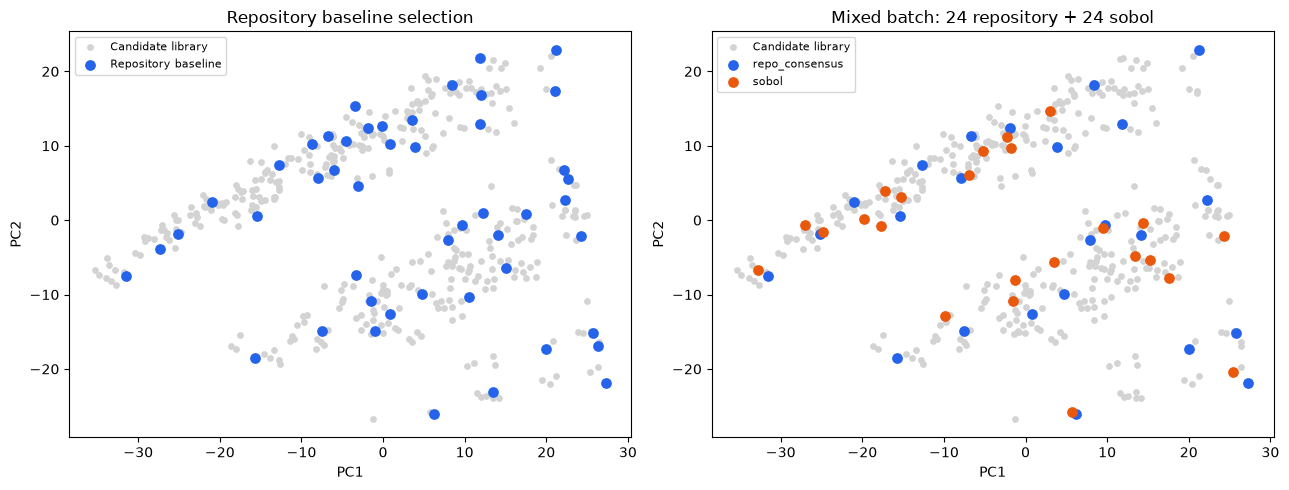

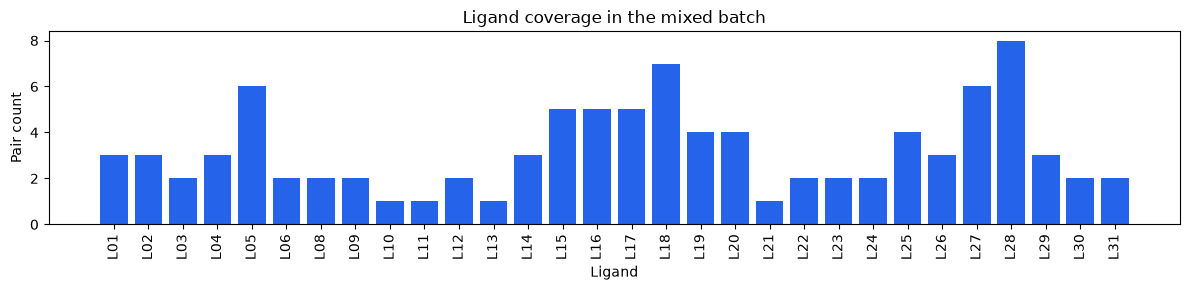

,ligand_id,name,pair_well_count
0,L01,MorDal Phos,3
1,L02,racBINAP,3
2,L03,RockPhos,2
3,L04,Alphos,3
4,L05,AdBrettPhos,6
5,L06,Me4t-BuXPhos,2
6,L08,t-BuDave Phos,2
7,L09,Xantphos,2
8,L10,OTIPS DalPhos,1
9,L11,Me3OMe-t-BuXPhos,1


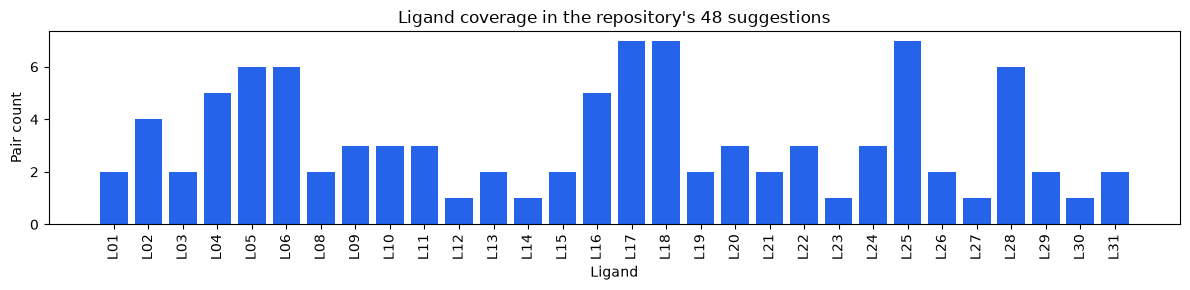

,ligand_id,name,pair_well_count
0,L01,MorDal Phos,2
1,L02,racBINAP,4
2,L03,RockPhos,2
3,L04,Alphos,5
4,L05,AdBrettPhos,6
5,L06,Me4t-BuXPhos,6
6,L08,t-BuDave Phos,2
7,L09,Xantphos,3
8,L10,OTIPS DalPhos,3
9,L11,Me3OMe-t-BuXPhos,3


In [92]:
counts = pd.concat([suggestions["ligand_a"], suggestions["ligand_b"]]).value_counts()
coverage = pd.DataFrame([
    {"ligand_id": key, "name": inventory[key]["name"], "pair_well_count": int(counts.get(key, 0))}
    for key in sorted(inventory)
])
print(f"Ligands covered: {(coverage['pair_well_count'] > 0).sum()}/{len(inventory)}")
missing_ligands = coverage.loc[coverage["pair_well_count"] == 0, "ligand_id"].tolist()
if REQUIRE_ALL_LIGANDS and missing_ligands:
    raise ValueError(
        "Mixed batch is missing ligands: " + ", ".join(missing_ligands)
        + ". Increase KEEP_FROM_REPO or BATCH_SIZE, or set REQUIRE_ALL_LIGANDS = False."
    )

index_by_id = {row["pair_id"]: i for i, row in enumerate(all_candidates)}
# With one retained PCA dimension, use zero as the second plotting coordinate.
plot_x = pca_components[:, 0]
plot_y = pca_components[:, 1] if PCA_DIMENSIONS > 1 else np.zeros(len(all_candidates))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax in axes:
    ax.scatter(plot_x, plot_y, s=15, color="lightgray", label="Candidate library")
base_idx = [index_by_id[key] for key in baseline_ids]
axes[0].scatter(plot_x[base_idx], plot_y[base_idx], s=45, color="#2563eb", label="Repository baseline")
axes[0].set_title("Repository baseline selection")
for source, color in (("repo_consensus", "#2563eb"), (SAMPLER, "#ea580c")):
    ids = suggestions.loc[suggestions["selection_source"] == source, "pair_id"]
    idx = [index_by_id[key] for key in ids]
    if idx:
        axes[1].scatter(plot_x[idx], plot_y[idx], s=45, color=color, label=source)
axes[1].set_title(f"Mixed batch: {KEEP_FROM_REPO} repository + {BATCH_SIZE-KEEP_FROM_REPO} {SAMPLER}")
for ax in axes:
    ax.set(xlabel="PC1", ylabel="PC2" if PCA_DIMENSIONS > 1 else "No second component")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(coverage["ligand_id"], coverage["pair_well_count"], color="#2563eb")
ax.set(xlabel="Ligand", ylabel="Pair count", title="Ligand coverage in the mixed batch")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()
display(coverage)

# Retrieve the full repository baseline.
baseline_pairs = candidate_table.set_index("pair_id").loc[baseline_ids]

baseline_counts = pd.concat([
    baseline_pairs["ligand_a"],
    baseline_pairs["ligand_b"],
]).value_counts()

baseline_coverage = pd.DataFrame([
    {
        "ligand_id": key,
        "name": inventory[key]["name"],
        "pair_well_count": int(baseline_counts.get(key, 0)),
    }
    for key in sorted(inventory)
])

fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(
    baseline_coverage["ligand_id"],
    baseline_coverage["pair_well_count"],
    color="#2563eb",
)
ax.set(
    xlabel="Ligand",
    ylabel="Pair count",
    title=f"Ligand coverage in the repository's {len(baseline_ids)} suggestions",
)
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

display(baseline_coverage)


## 9. Optional export

Results are already available as `suggestions`, `coverage` and `features`. With `SAVE_RESULTS = False`, the next cells write nothing.

To export, set `SAVE_RESULTS = True` in the settings cell, rerun that settings cell and then this section. It creates a new timestamped proposal directory under `output/notebook_batches/`, containing CSVs and settings. Selection order is not a plate well assignment.


In [90]:
def save_suggestions(directory, suggestions, baseline_trace, prompts, settings):
    """Write a new reviewable proposal directory; never overwrite an earlier run."""
    out = new_output(directory)
    write_csv(out / "suggested_batch.csv", suggestions)
    write_csv(out / "baseline_selection.csv", baseline_trace)
    write_csv(out / "candidate_prompts.csv", prompts)
    write_json(out / "settings.json", settings)
    return out


In [91]:
if SAVE_RESULTS:
    run_name = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ") + f"_{SAMPLER}"
    output_directory = REPO_ROOT / "output/notebook_batches" / run_name
    prompt_rows = [
        {"pair_id": row["pair_id"], "prompt": ordered_prompts[2*i], "reversed_prompt": ordered_prompts[2*i+1]}
        for i, row in enumerate(all_candidates)
    ]
    settings = {
        "batch_size": BATCH_SIZE, "keep_from_repo": KEEP_FROM_REPO, "sampler": SAMPLER,
        "repository_subset_method": "diversity_scaled_pca", "retained_repository_pair_ids": retained_repo_ids,
        "repository_subset_required_ligands": sorted(subset_required_ligands),
        "pca_dimensions": PCA_DIMENSIONS, "seed": SEED, "require_all_ligands": REQUIRE_ALL_LIGANDS,
        "baseline_llm_weight": config["design"]["consensus_weight_llm"],
        "baseline_minimum_llm_percentile": config["design"]["minimum_llm_percentile"],
        "sampling_uses_claude_floor": False, "prompt_template": PROMPT_TEMPLATE,
        "embedding": embedding_info,
        "ranking_path": str(RANKING_CSV), "ranking_sha256": digest(RANKING_CSV),
        "config_sha256": digest(CONFIG_PATH), "inventory_sha256": digest(LIGAND_COLLECTION_PATH),
        "excluded_pair_ids": sorted(excluded),
        "previous_experiments_sha256": digest(PREVIOUS_EXPERIMENTS_CSV) if PREVIOUS_EXPERIMENTS_CSV else None,
        "pca_explained_variance_ratio": explained_variance.tolist(),
        "python": sys.version,
        "packages": {name: importlib.metadata.version(name)
                     for name in ("numpy", "scipy", "scikit-learn", "pandas", "torch", "transformers")},
        "proposal_only": True,
    }
    output_directory = save_suggestions(
        output_directory, suggestions.to_dict("records"), baseline_trace, prompt_rows, settings,
    )
    coverage.to_csv(output_directory / "ligand_coverage.csv", index=False)
    print(f"Saved: {output_directory}")
    print("Open suggested_batch.csv in Excel or another spreadsheet application.")
else:
    print("Results are in memory: suggestions, coverage and features. SAVE_RESULTS is False; nothing exported.")


Results are in memory: suggestions, coverage and features. SAVE_RESULTS is False; nothing exported.


## Try another proposal

1. Change `SAMPLER` to `"maxmin"` or `"sobol"`, or adjust `KEEP_FROM_REPO`.
2. Rerun from section 4 onward. If you change the prompt, rerun from section 3.
3. Compare the plots and tables; export only when wanted. Change `SEED` to examine sampling sensitivity.

For an exclusion-only next batch, set `PREVIOUS_EXPERIMENTS_CSV` to the earlier `suggested_batch.csv`. For selection informed by measured yields, first use the repository's calibrated LC/Claude feedback workflow and provide its updated ranking alongside the exclusion CSV. Do not interpret exclusion as model learning.

### Troubleshooting

- **Missing package:** follow the installation commands in [README.md](README.md), restart the kernel, then run again.
- **No GPU attached:** launch Jupyter inside a GPU allocation using [README.md](README.md), and connect the notebook to that server. A login-node kernel has no GPU.
- **Model download fails:** use the downloaded model cache or point `MODEL_PATH` at a local T5-base folder.
- **PCA dimensions too large:** reduce `PCA_DIMENSIONS` to the range shown in the error.
- **Mixed batch is missing ligands:** increase `KEEP_FROM_REPO` or `BATCH_SIZE`, or turn off `REQUIRE_ALL_LIGANDS` if complete coverage is not needed. Coverage is checked afterward rather than forced during sampling.
- **Claude cutoff leaves too few pairs:** use a smaller batch; the original baseline preserves the campaign's cutoff even if you keep zero baseline points.
- **Ranking mismatch:** the CSV needs each active-library pair once, plus `mean_score` and `score_sd`. A round-two ranking containing only untested pairs works directly when the matching previous-experiments CSV is supplied.

### Method references

- [Local repository consensus selection](../hte/design.py) and [original T5 embeddings](../hte/adapters.py).
- [ALICE initializer: standardization, optional PCA, scaling, Sobol and unique matching](https://github.com/schwallergroup/alice/blob/cda460d627e074d3cd57c47df13df08cea9346c6/src/alice/initialization/initializers.py).
- [ALICE T5 / 16-component PCA configuration](https://github.com/schwallergroup/alice/blob/cda460d627e074d3cd57c47df13df08cea9346c6/configs/pd_suzuki/pd_suzuki_llm.yaml).
- [SciPy Sobol engine and balance limitations](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.qmc.Sobol.html).

All added code is contained in this notebook: prompt creation, direct GPU inference, PCA, sampling and optional export. The repository's original source files are unchanged.
